# The version timeline: v1 min-max → v6 deployed

The six versions of the engine head to head: v1 naive min-max, v2 alpha-beta, v3 tuned weights, v4 quiescence + pruning + book, v5 the forced-win layer, v6 the parallel split root.

In [1]:
import os
import sys
import time
from dataclasses import dataclass
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tuning" / "default.json").is_file())
os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "default.json")
os.environ["V6_JOBS"] = "1"
sys.path.insert(0, str(ROOT / "tuning"))

import genetic_tuner as gt
import harness
from connect6.defines import Color, SearchStats
from connect6.opening_book import book_move, load_opening_book
from connect6.parallel import search_v6
from connect6.protocol import move2msg
from connect6.search import search_alpha_beta, search_alpha_beta_with_quiescence, search_min_max
from connect6.vcf import search_v5

DEPTH = 3
MAX_PLIES = 60


@dataclass(frozen=True, slots=True)
class Version:
    name: str
    weights: gt.Weights
    search: str
    use_book: bool


champion = harness.load_weights(ROOT / "tuning" / "winner.json")
VERSIONS = [
    Version("v1 min-max", gt.BASE, "min_max", False),
    Version("v2 alpha-beta", gt.BASE, "alpha_beta", False),
    Version("v3 alpha-beta + tuned weights", champion, "alpha_beta", False),
    Version("v4 + quiescence, pruning, book", champion, "enhanced", True),
    Version("v5 + forced-win layer", champion, "v5", True),
    Version("v6 + parallel split, budget", champion, "v6", True),
]
SEARCHES = {
    "min_max": search_min_max,
    "alpha_beta": search_alpha_beta,
    "enhanced": search_alpha_beta_with_quiescence,
    "v5": search_v5,
    "v6": search_v6,
}
BOOK = load_opening_book()

print(f"weights pinned to {os.environ['WEIGHTS_FILE']} (installed per search by the referee)")
for version in VERSIONS:
    print(f"  {version.name}: {gt.fmt(version.weights)}")


weights pinned to /Users/e.butovka/Documents/MyProjects/Connect6Engine/tuning/default.json (installed per search by the referee)
  v1 min-max: tiers=(1, 10, 100, 1000, 10000) factor=(2, 3) threat=1000
  v2 alpha-beta: tiers=(1, 10, 100, 1000, 10000) factor=(2, 3) threat=1000
  v3 alpha-beta + tuned weights: tiers=(1, 18, 93, 716, 10000) factor=(1, 3) threat=1724
  v4 + quiescence, pruning, book: tiers=(1, 18, 93, 716, 10000) factor=(1, 3) threat=1724
  v5 + forced-win layer: tiers=(1, 18, 93, 716, 10000) factor=(1, 3) threat=1724
  v6 + parallel split, budget: tiers=(1, 18, 93, 716, 10000) factor=(1, 3) threat=1724


## Who is winning

Every game is one deterministic pairing; the v4/v5/v6 players consult the opening book before searching.

In [2]:
def think(version, board, color, depth, pre_move, stats):
    if version.use_book:
        booked = book_move(board, BOOK)
        if booked is not None:
            return booked, None
    gt.apply_weights(version.weights)
    result = SEARCHES[version.search](board, color, depth, pre_move, stats)
    return result.move, result.score


def timed_think(version, board, color, depth, pre_move, tally):
    stats = SearchStats()
    start = time.perf_counter()
    move, score = think(version, board, color, depth, pre_move, stats)
    tally.ms += (time.perf_counter() - start) * 1000
    tally.nodes += stats.node_count
    tally.moves += 1
    if version.use_book and stats.node_count == 0:
        tally.book_hits += 1
    return move, score


def make_spec(version):
    return harness.PlayerSpec(SEARCHES[version.search], version.weights, version.use_book)


pairings = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (0, 5)]
plans = []
for left, right in pairings:
    for black_first in (True, False):
        black_version = VERSIONS[left] if black_first else VERSIONS[right]
        white_version = VERSIONS[right] if black_first else VERSIONS[left]
        plans.append((black_version, white_version,
                      harness.GameSpec(make_spec(black_version), make_spec(white_version), DEPTH, MAX_PLIES)))

start = time.perf_counter()
records = harness.run_games([plan[2] for plan in plans])
print(f"== games: adjacent steps of the timeline, plus the full journey ({time.perf_counter() - start:.0f} s across twelve workers) ==")
game_rows = []
for (black_version, white_version, _), record in zip(plans, records):
    if record.winner is None:
        outcome, who = "draw", "nobody"
    else:
        outcome = f"{'black' if record.winner is Color.BLACK else 'white'} wins"
        who = black_version.name if record.winner is Color.BLACK else white_version.name
    extras = []
    if record.black.book_hits:
        extras.append(f"black book hits {record.black.book_hits}")
    if record.white.book_hits:
        extras.append(f"white book hits {record.white.book_hits}")
    print(
        f"{black_version.name} (black) vs {white_version.name} (white): "
        f"{outcome} — {who}, ply {record.plies} | "
        f"black: {record.black.moves} moves, {record.black.nodes} nodes, {record.black.ms / max(record.black.moves, 1):.0f} ms/move | "
        f"white: {record.white.moves} moves, {record.white.nodes} nodes, {record.white.ms / max(record.white.moves, 1):.0f} ms/move"
        + (" | " + ", ".join(extras) if extras else "")
    )
    game_rows.append((black_version.name, white_version.name, outcome, who, record.plies,
                      record.black.book_hits, record.white.book_hits))
print()


== games: adjacent steps of the timeline, plus the full journey (1084 s across twelve workers) ==
v1 min-max (black) vs v2 alpha-beta (white): black wins — v1 min-max, ply 38 | black: 19 moves, 523459 nodes, 4017 ms/move | white: 19 moves, 36379 nodes, 350 ms/move
v2 alpha-beta (black) vs v1 min-max (white): black wins — v2 alpha-beta, ply 38 | black: 19 moves, 29266 nodes, 301 ms/move | white: 19 moves, 526489 nodes, 3990 ms/move
v2 alpha-beta (black) vs v3 alpha-beta + tuned weights (white): white wins — v3 alpha-beta + tuned weights, ply 17 | black: 8 moves, 14559 nodes, 289 ms/move | white: 9 moves, 16675 nodes, 300 ms/move
v3 alpha-beta + tuned weights (black) vs v2 alpha-beta (white): black wins — v3 alpha-beta + tuned weights, ply 36 | black: 18 moves, 31116 nodes, 372 ms/move | white: 18 moves, 29910 nodes, 347 ms/move
v3 alpha-beta + tuned weights (black) vs v4 + quiescence, pruning, book (white): white wins — v4 + quiescence, pruning, book, ply 19 | black: 9 moves, 16562 node

## Validation

The cell below re-checks every game: outcome, winner, ply and the book-hit pattern.

In [3]:
EXPECTED_GAMES = [
    ("v1 min-max", "v2 alpha-beta", "black wins", "v1 min-max", 38, 0, 0),
    ("v2 alpha-beta", "v1 min-max", "black wins", "v2 alpha-beta", 38, 0, 0),
    ("v2 alpha-beta", "v3 alpha-beta + tuned weights", "white wins", "v3 alpha-beta + tuned weights", 17, 0, 0),
    ("v3 alpha-beta + tuned weights", "v2 alpha-beta", "black wins", "v3 alpha-beta + tuned weights", 36, 0, 0),
    ("v3 alpha-beta + tuned weights", "v4 + quiescence, pruning, book", "white wins", "v4 + quiescence, pruning, book", 19, 0, 1),
    ("v4 + quiescence, pruning, book", "v3 alpha-beta + tuned weights", "black wins", "v4 + quiescence, pruning, book", 26, 0, 0),
    ("v4 + quiescence, pruning, book", "v5 + forced-win layer", "white wins", "v5 + forced-win layer", 37, 5, 5),
    ("v5 + forced-win layer", "v4 + quiescence, pruning, book", "white wins", "v4 + quiescence, pruning, book", 19, 5, 5),
    ("v5 + forced-win layer", "v6 + parallel split, budget", "white wins", "v6 + parallel split, budget", 19, 5, 5),
    ("v6 + parallel split, budget", "v5 + forced-win layer", "white wins", "v5 + forced-win layer", 19, 5, 5),
    ("v1 min-max", "v6 + parallel split, budget", "white wins", "v6 + parallel split, budget", 19, 0, 1),
    ("v6 + parallel split, budget", "v1 min-max", "black wins", "v6 + parallel split, budget", 54, 0, 0),
]
assert game_rows == EXPECTED_GAMES
assert records[8].moves == records[9].moves, "the v5-v6 pairing must be one game played twice"
print("all 12 games reproduce exactly (outcome, winner, ply, book hits)")
print("the v5-vs-v6 games are move-for-move identical in both color assignments")


all 12 games reproduce exactly (outcome, winner, ply, book hits)
the v5-vs-v6 games are move-for-move identical in both color assignments


## What it costs

One search per position per version, deterministic; the v5/v6 rows are budget answers.

In [4]:
cost_rows = {}
positions = harness.documented_positions()
for depth in (DEPTH, DEPTH + 1):
    rows = [v for v in VERSIONS if depth == DEPTH or v.search != "min_max"]
    note = "" if len(rows) == len(VERSIONS) else " (min-max omitted: the naive depth-4 trees are minutes long)"
    print(f"== timing and nodes at depth {depth}{note} ==")
    print(f"{'position':34s} {'version':38s} {'nodes':>8s} {'ms':>8s} {'score':>7s}  move")
    for label, board, color, pre_move in positions:
        for version in rows:
            tally = harness.Tally()
            stats = SearchStats()
            start = time.perf_counter()
            booked = book_move(board, BOOK) if version.use_book else None
            if booked is not None:
                move, score = booked, None
                tally.ms += (time.perf_counter() - start) * 1000
            else:
                gt.apply_weights(version.weights)
                result = SEARCHES[version.search](board, color, depth, pre_move, stats)
                move, score = result.move, result.score
                tally.ms += (time.perf_counter() - start) * 1000
                tally.nodes += stats.node_count
            depth_note = f" (d{stats.depth_reached})" if version.search == "v6" and tally.nodes > 0 else ""
            print(
                f"{label:34s} {version.name:38s} {tally.nodes:8d} {tally.ms:8.1f} "
                f"{'book' if score is None else str(score):>7}  {move2msg(move)}{depth_note}"
            )
            cost_rows[(depth, label, version.name)] = (tally.nodes, score, move2msg(move))
    print()


== timing and nodes at depth 3 ==
position                           version                                   nodes       ms   score  move


opening reply, white to move       v1 min-max                                27931   1437.5    -303  IJJK


opening reply, white to move       v2 alpha-beta                              2830    219.0    -303  IJJK
opening reply, white to move       v3 alpha-beta + tuned weights              2918    222.5    -282  IJJK
opening reply, white to move       v4 + quiescence, pruning, book                0      0.0    book  IIKK
opening reply, white to move       v5 + forced-win layer                         0      0.0    book  IIKK
opening reply, white to move       v6 + parallel split, budget                   0      0.0    book  IIKK


opening scatter, white to move     v1 min-max                                27931   1784.0    -510  KQCK
opening scatter, white to move     v2 alpha-beta                              1182    114.4    -510  KQCK


opening scatter, white to move     v3 alpha-beta + tuned weights              1593    140.5    -436  CIIP


opening scatter, white to move     v4 + quiescence, pruning, book             1668    324.7    -386  CKJP


... (24 outputs left out)

fork completed, white to move      v3 alpha-beta + tuned weights               573    180.5   20000  GJHJ
fork completed, white to move      v4 + quiescence, pruning, book              349    113.4   20000  GJHJ


fork completed, white to move      v5 + forced-win layer                       350    114.5   20000  GJHJ
fork completed, white to move      v6 + parallel split, budget                 488    154.5   20000  GJHJ (d4)


five-run attack, white to move     v2 alpha-beta                              1616    192.1   11613  HJBJ
five-run attack, white to move     v3 alpha-beta + tuned weights              1616    192.3   11596  HJBJ


five-run attack, white to move     v4 + quiescence, pruning, book              110     30.5   20000  HJBJ
five-run attack, white to move     v5 + forced-win layer                       111     32.6   20000  HJBJ
five-run attack, white to move     v6 + parallel split, budget                 111     32.2   20000  HJBJ (d4)



In [5]:
EXPECTED_COST = {
    (3, "opening reply, white to move", "v1 min-max"): (27931, -303, "IJJK"),
    (3, "opening reply, white to move", "v2 alpha-beta"): (2830, -303, "IJJK"),
    (3, "opening reply, white to move", "v3 alpha-beta + tuned weights"): (2918, -282, "IJJK"),
    (3, "opening reply, white to move", "v4 + quiescence, pruning, book"): (0, None, "IIKK"),
    (3, "opening reply, white to move", "v5 + forced-win layer"): (0, None, "IIKK"),
    (3, "opening reply, white to move", "v6 + parallel split, budget"): (0, None, "IIKK"),
    (3, "opening scatter, white to move", "v1 min-max"): (27931, -510, "KQCK"),
    (3, "opening scatter, white to move", "v2 alpha-beta"): (1182, -510, "KQCK"),
    (3, "opening scatter, white to move", "v3 alpha-beta + tuned weights"): (1593, -436, "CIIP"),
    (3, "opening scatter, white to move", "v4 + quiescence, pruning, book"): (1668, -386, "CKJP"),
    (3, "opening scatter, white to move", "v5 + forced-win layer"): (76694, -336, "IKKP"),
    (3, "opening scatter, white to move", "v6 + parallel split, budget"): (42303, -38, "CKJP"),
    (3, "midgame, white to move", "v1 min-max"): (27931, -3097, "FJII"),
    (3, "midgame, white to move", "v2 alpha-beta"): (1390, -3097, "FJII"),
    (3, "midgame, white to move", "v3 alpha-beta + tuned weights"): (1425, -2342, "FJII"),
    (3, "midgame, white to move", "v4 + quiescence, pruning, book"): (1458, -703, "BJII"),
    (3, "midgame, white to move", "v5 + forced-win layer"): (23420, -1060, "JGKI"),
    (3, "midgame, white to move", "v6 + parallel split, budget"): (38421, -617, "JGII"),
    (3, "fork attack, black to move", "v1 min-max"): (27931, 20000, "JNBJ"),
    (3, "fork attack, black to move", "v2 alpha-beta"): (78, 20000, "JNBJ"),
    (3, "fork attack, black to move", "v3 alpha-beta + tuned weights"): (78, 20000, "JNBJ"),
    (3, "fork attack, black to move", "v4 + quiescence, pruning, book"): (78, 20000, "JNBJ"),
    (3, "fork attack, black to move", "v5 + forced-win layer"): (18, 20000, "JSFJ"),
    (3, "fork attack, black to move", "v6 + parallel split, budget"): (18, 20000, "JSFJ"),
    (3, "fork completed, white to move", "v1 min-max"): (24631, 20000, "GJHJ"),
    (3, "fork completed, white to move", "v2 alpha-beta"): (351, 20000, "GJHJ"),
    (3, "fork completed, white to move", "v3 alpha-beta + tuned weights"): (347, 20000, "GJHJ"),
    (3, "fork completed, white to move", "v4 + quiescence, pruning, book"): (207, 20000, "GJHJ"),
    (3, "fork completed, white to move", "v5 + forced-win layer"): (208, 20000, "GJHJ"),
    (3, "fork completed, white to move", "v6 + parallel split, budget"): (280, 20000, "GJHJ"),
    (3, "five-run attack, white to move", "v1 min-max"): (14461, 1577, "HJBJ"),
    (3, "five-run attack, white to move", "v2 alpha-beta"): (249, 1577, "HJBJ"),
    (3, "five-run attack, white to move", "v3 alpha-beta + tuned weights"): (249, 1536, "HJBJ"),
    (3, "five-run attack, white to move", "v4 + quiescence, pruning, book"): (103, 20000, "HJBJ"),
    (3, "five-run attack, white to move", "v5 + forced-win layer"): (104, 20000, "HJBJ"),
    (3, "five-run attack, white to move", "v6 + parallel split, budget"): (121, 20000, "HJBJ"),
    (4, "opening reply, white to move", "v2 alpha-beta"): (24533, 303, "IJJK"),
    (4, "opening reply, white to move", "v3 alpha-beta + tuned weights"): (25469, 282, "IJJK"),
    (4, "opening reply, white to move", "v4 + quiescence, pruning, book"): (0, None, "IIKK"),
    (4, "opening reply, white to move", "v5 + forced-win layer"): (0, None, "IIKK"),
    (4, "opening reply, white to move", "v6 + parallel split, budget"): (0, None, "IIKK"),
    (4, "opening scatter, white to move", "v2 alpha-beta"): (9150, -66, "KQCK"),
    (4, "opening scatter, white to move", "v3 alpha-beta + tuned weights"): (15964, -40, "CKJP"),
    (4, "opening scatter, white to move", "v4 + quiescence, pruning, book"): (7581, -38, "CKJP"),
    (4, "opening scatter, white to move", "v5 + forced-win layer"): (75026, -336, "IKKP"),
    (4, "opening scatter, white to move", "v6 + parallel split, budget"): (234625, -336, "IKKP"),
    (4, "midgame, white to move", "v2 alpha-beta"): (11640, -301, "FJKI"),
    (4, "midgame, white to move", "v3 alpha-beta + tuned weights"): (11799, -305, "FJKI"),
    (4, "midgame, white to move", "v4 + quiescence, pruning, book"): (3782, -617, "JGII"),
    (4, "midgame, white to move", "v5 + forced-win layer"): (21962, -1060, "JGKI"),
    (4, "midgame, white to move", "v6 + parallel split, budget"): (207226, -1060, "JGKI"),
    (4, "fork attack, black to move", "v2 alpha-beta"): (350, 20000, "JNBJ"),
    (4, "fork attack, black to move", "v3 alpha-beta + tuned weights"): (347, 20000, "JNBJ"),
    (4, "fork attack, black to move", "v4 + quiescence, pruning, book"): (179, 20000, "JNBJ"),
    (4, "fork attack, black to move", "v5 + forced-win layer"): (18, 20000, "JSFJ"),
    (4, "fork attack, black to move", "v6 + parallel split, budget"): (18, 20000, "JSFJ"),
    (4, "fork completed, white to move", "v2 alpha-beta"): (577, 20000, "GJHJ"),
    (4, "fork completed, white to move", "v3 alpha-beta + tuned weights"): (573, 20000, "GJHJ"),
    (4, "fork completed, white to move", "v4 + quiescence, pruning, book"): (349, 20000, "GJHJ"),
    (4, "fork completed, white to move", "v5 + forced-win layer"): (350, 20000, "GJHJ"),
    (4, "fork completed, white to move", "v6 + parallel split, budget"): (488, 20000, "GJHJ"),
    (4, "five-run attack, white to move", "v2 alpha-beta"): (1616, 11613, "HJBJ"),
    (4, "five-run attack, white to move", "v3 alpha-beta + tuned weights"): (1616, 11596, "HJBJ"),
    (4, "five-run attack, white to move", "v4 + quiescence, pruning, book"): (110, 20000, "HJBJ"),
    (4, "five-run attack, white to move", "v5 + forced-win layer"): (111, 20000, "HJBJ"),
    (4, "five-run attack, white to move", "v6 + parallel split, budget"): (111, 20000, "HJBJ"),
}

for key, expected in EXPECTED_COST.items():
    measured = cost_rows[key]
    assert measured == expected, f"{key}: measured {measured}, expected {expected}"
print(f"all {len(EXPECTED_COST)} cost rows reproduce exactly (nodes, score, move)")


all 66 cost rows reproduce exactly (nodes, score, move)


## The genealogy of the tree

The common trajectory re-analyzed by all six versions at the deployment depth.

In [6]:
import json

trajectory_record = json.loads((ROOT / "benchmarks" / "trajectory.json").read_text())
trajectory_history = trajectory_record["history"]
assert trajectory_history[0] == "JJ" and len(trajectory_history) == 49

GENEALOGY = [
    ("v1 min-max", "naive full width"),
    ("v2 alpha-beta", "window cutoffs"),
    ("v3 alpha-beta, tuned weights", "ordering for cutoffs"),
    ("v4 quiescence + pruning", "verdict truth"),
    ("v5 forced-win layer", "proven wins"),
    ("v6 split root + PVS", "the parallel wall"),
]

os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "winner.json")
tuned_rows = harness.analyze_history(trajectory_history, [
    ("v3 alpha-beta, tuned weights", SEARCHES["alpha_beta"]),
    ("v4 quiescence + pruning", SEARCHES["enhanced"]),
    ("v5 forced-win layer", SEARCHES["v5"]),
    ("v6 split root + PVS", SEARCHES["v6"]),
], DEPTH, jobs=12)
os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "default.json")
base_rows = harness.analyze_history(trajectory_history, [
    ("v1 min-max", SEARCHES["min_max"]),
    ("v2 alpha-beta", SEARCHES["alpha_beta"]),
], DEPTH, jobs=12)

genealogy = {}
for row in tuned_rows + base_rows:
    genealogy.setdefault(row.prefix, {})[row.name] = row
genealogy_positions = sorted(genealogy)
genealogy_totals = {}
print(f"the common trajectory, {len(genealogy_positions)} decision points, depth {DEPTH}, era configurations")
print(f"{'version':32s} {'feature':26s} {'total nodes':>12s} {'x previous':>10s} {'mean':>8s} {'peak':>9s}")
previous = None
for name, feature in GENEALOGY:
    nodes = [genealogy[p][name].nodes for p in genealogy_positions]
    total = sum(nodes)
    genealogy_totals[name] = total
    growth = "-" if previous is None else f"x{total / previous:.2f}"
    print(f"{name:32s} {feature:26s} {total:>12,d} {growth:>10s} "
          f"{total // len(genealogy_positions):>8,d} {max(nodes):>9,d}")
    previous = total

the common trajectory, 48 decision points, depth 3, era configurations
version                          feature                     total nodes x previous     mean      peak
v1 min-max                       naive full width              1,326,648          -   27,638    27,931
v2 alpha-beta                    window cutoffs                   84,979      x0.06    1,770     4,322
v3 alpha-beta, tuned weights     ordering for cutoffs             84,596      x1.00    1,762     3,847
v4 quiescence + pruning          verdict truth                   320,038      x3.78    6,667    40,262
v5 forced-win layer              proven wins                   1,415,330      x4.42   29,486   233,374
v6 split root + PVS              the parallel wall             3,201,750      x2.26   66,703   226,843


In [7]:
EXPECTED_GENEALOGY = {
    "v1 min-max": (1326648, 27931),
    "v2 alpha-beta": (84979, 4322),
    "v3 alpha-beta, tuned weights": (84596, 3847),
    "v4 quiescence + pruning": (320038, 40262),
    "v5 forced-win layer": (1415330, 233374),
    "v6 split root + PVS": (3201750, 226843),
}
for name, (total, peak) in EXPECTED_GENEALOGY.items():
    nodes = [genealogy[p][name].nodes for p in genealogy_positions]
    assert (sum(nodes), max(nodes)) == (total, peak), name
print("the genealogy reproduces the v4/v5/v6 notebooks' trajectory pins exactly "
      "(320,038 / 1,415,330 / 3,201,750) and pins the v1/v2/v3 baselines")

the genealogy reproduces the v4/v5/v6 notebooks' trajectory pins exactly (320,038 / 1,415,330 / 3,201,750) and pins the v1/v2/v3 baselines


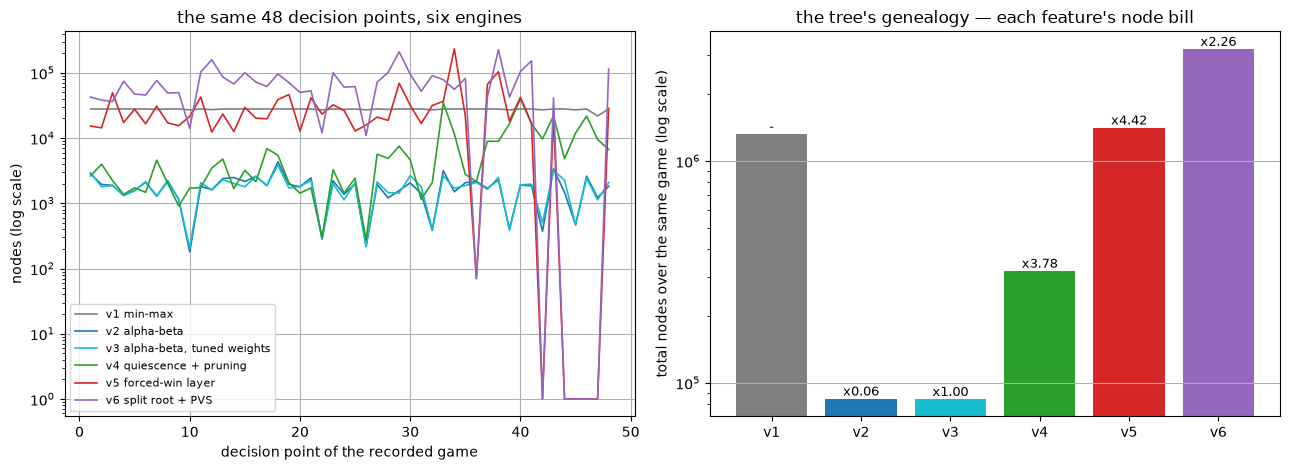

In [8]:
import matplotlib.pyplot as plt

palette = ["tab:gray", "tab:blue", "tab:cyan", "tab:green", "tab:red", "tab:purple"]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for (name, _), color in zip(GENEALOGY, palette):
    ax.plot(genealogy_positions, [genealogy[p][name].nodes for p in genealogy_positions],
            color=color, label=name, linewidth=1.2)
ax.set_yscale("log")
ax.set_xlabel("decision point of the recorded game")
ax.set_ylabel("nodes (log scale)")
ax.set_title("the same 48 decision points, six engines")
ax.grid(True)
ax.legend(fontsize=8)

totals = [genealogy_totals[name] for name, _ in GENEALOGY]
labels = [name.split()[0] for name, _ in GENEALOGY]
bars = ax2.bar(labels, totals, color=palette)
ax2.set_yscale("log")
for bar, total, previous in zip(bars, totals, [None, *totals[:-1]]):
    label = "-" if previous is None else f"x{total / previous:.2f}"
    ax2.annotate(label, (bar.get_x() + bar.get_width() / 2, total), ha="center", va="bottom", fontsize=9)
ax2.set_ylabel("total nodes over the same game (log scale)")
ax2.set_title("the tree's genealogy — each feature's node bill")
ax2.grid(True, axis="y")
plt.tight_layout()
plt.show()

## Charts


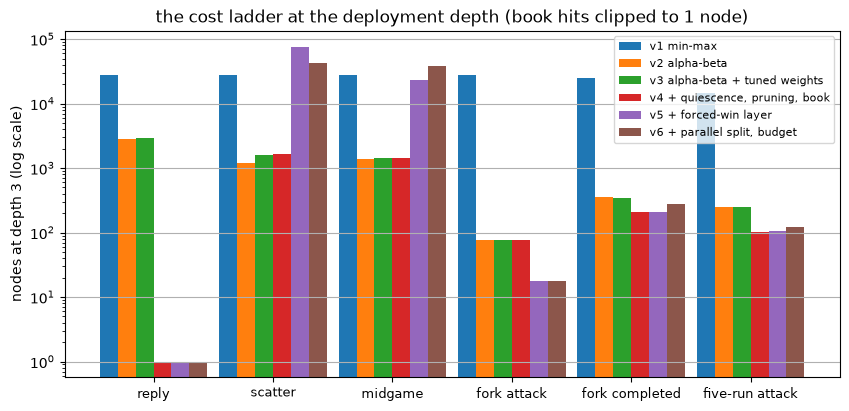

In [9]:
import matplotlib.pyplot as plt

labels = [label for label, *_ in positions]
short = [label.split(",")[0].replace("opening ", "") for label in labels]
width = 0.15
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, version in enumerate(VERSIONS):
    nodes = [max(cost_rows[(3, label, version.name)][0], 1) for label in labels]
    ax.bar([j + (i - 2.5) * width for j in range(len(labels))], nodes, width, label=version.name)
ax.set_yscale("log")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(short, fontsize=9)
ax.set_ylabel("nodes at depth 3 (log scale)")
ax.set_title("the cost ladder at the deployment depth (book hits clipped to 1 node)")
ax.grid(True, axis="y")
ax.legend(fontsize=8)
plt.show()


## Reading the results

v1 and v2 are the same player, the weights alone win games, and the enhancements carry them to full games.